<h1 align='center' style='color:purple'>Clustering With K Means - Python Tutorial</h1>

## 3. The K-Means algorithm and its objective function

### 3.1 Steps

1. **Choose K** – the number of clusters.
2. **Initialise** K centroids $\mu_1, \dots, \mu_K$ (randomly picked points, or the smarter *k-means++* in scikit-learn).
3. **Assignment step** – give each point $x_i$ to the closest centroid using **Euclidean distance**:
$$d(x, \mu) = \sqrt{(x_1-\mu_1)^2 + (x_2-\mu_2)^2 + \dots}$$
$$c_i = \arg\min_{k}\; d(x_i, \mu_k)$$
4. **Update step** – move every centroid to the **mean** of the points assigned to it:
$$\mu_k = \frac{1}{|C_k|}\sum_{x_i \in C_k} x_i$$
5. **Repeat** steps 3–4 until the assignments (or centroids) stop changing — this is **convergence**.

### 3.2 What K-Means is minimising

K-Means minimises the **Within-Cluster Sum of Squares (WCSS)**, which scikit-learn calls **`inertia_`**:

$$\text{WCSS} = \sum_{k=1}^{K}\;\sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$$

* Each assignment step and each update step can only **decrease (or keep)** the WCSS ⇒ the algorithm is guaranteed to converge.
* But it converges to a **local** minimum, which depends on the starting centroids. That is why scikit-learn runs it several times (`n_init`) and keeps the best result.

## 4. Numerical worked example (by hand) ✍️

Let's cluster **7 points** into **K = 2** clusters completely by hand, and then let Python confirm every number.

| Point | x | y |
|---|---|---|
| A | 1.0 | 1.0 |
| B | 1.5 | 2.0 |
| C | 3.0 | 4.0 |
| D | 5.0 | 7.0 |
| E | 3.5 | 5.0 |
| F | 4.5 | 5.0 |
| G | 3.5 | 4.5 |

**Initial centroids** (chosen as two far-apart points): $\mu_1 = A = (1, 1)$ and $\mu_2 = D = (5, 7)$.

---

### 🔁 Iteration 1

**Assignment step.** Example calculation for point **B (1.5, 2)**:

$$d(B,\mu_1) = \sqrt{(1.5-1)^2 + (2-1)^2} = \sqrt{0.25+1} = \sqrt{1.25} = 1.118$$
$$d(B,\mu_2) = \sqrt{(1.5-5)^2 + (2-7)^2} = \sqrt{12.25+25} = \sqrt{37.25} = 6.103$$

$1.118 < 6.103$ ⇒ **B → Cluster 1**. Doing this for every point:

| Point | d to μ₁ (1, 1) | d to μ₂ (5, 7) | Assigned to |
|---|---|---|---|
| A | 0.000 | 7.211 | **C1** |
| B | 1.118 | 6.103 | **C1** |
| C | 3.606 | 3.606 | **C1** *(tie → first centroid)* |
| D | 7.211 | 0.000 | **C2** |
| E | 4.717 | 2.500 | **C2** |
| F | 5.315 | 2.062 | **C2** |
| G | 4.301 | 2.915 | **C2** |

> ⚠️ Point **C** is *exactly* the same distance from both centroids. By convention (and in NumPy's `argmin`) ties go to the **first** centroid.

**Update step.**

$$\mu_1 = \text{mean}(A,B,C) = \left(\tfrac{1+1.5+3}{3},\; \tfrac{1+2+4}{3}\right) = (1.833,\; 2.333)$$
$$\mu_2 = \text{mean}(D,E,F,G) = \left(\tfrac{5+3.5+4.5+3.5}{4},\; \tfrac{7+5+5+4.5}{4}\right) = (4.125,\; 5.375)$$

---

### 🔁 Iteration 2

| Point | d to μ₁ (1.833, 2.333) | d to μ₂ (4.125, 5.375) | Assigned to |
|---|---|---|---|
| A | 1.572 | 5.376 | C1 |
| B | 0.471 | 4.276 | C1 |
| C | 2.034 | **1.777** | **C2** ⬅ *changed!* |
| D | 5.640 | 1.846 | C2 |
| E | 3.145 | 0.729 | C2 |
| F | 3.771 | 0.530 | C2 |
| G | 2.734 | 1.075 | C2 |

Point **C** has moved to Cluster 2. **Update step:**

$$\mu_1 = \text{mean}(A,B) = (1.25,\; 1.5)$$
$$\mu_2 = \text{mean}(C,D,E,F,G) = \left(\tfrac{3+5+3.5+4.5+3.5}{5},\; \tfrac{4+7+5+5+4.5}{5}\right) = (3.9,\; 5.1)$$

---

### 🔁 Iteration 3

| Point | d to μ₁ (1.25, 1.5) | d to μ₂ (3.9, 5.1) | Assigned to |
|---|---|---|---|
| A | 0.559 | 5.022 | C1 |
| B | 0.559 | 3.920 | C1 |
| C | 3.052 | 1.421 | C2 |
| D | 6.657 | 2.195 | C2 |
| E | 4.161 | 0.412 | C2 |
| F | 4.776 | 0.608 | C2 |
| G | 3.750 | 0.721 | C2 |

No point changed cluster ⇒ the centroids stay at $(1.25, 1.5)$ and $(3.9, 5.1)$ ⇒ **converged ✅**

**Final clusters:** C1 = {A, B}, C2 = {C, D, E, F, G}

### 📉 WCSS at the end

$$\text{WCSS} = \underbrace{(0.25^2+0.5^2) + (0.25^2+0.5^2)}_{\text{C1: } A, B = 0.625} + \underbrace{(0.9^2+1.1^2) + (1.1^2+1.9^2) + (0.4^2+0.1^2) + (0.6^2+0.1^2) + (0.4^2+0.6^2)}_{\text{C2} = 7.9} = 8.525$$

WCSS went **33.25 → 11.23 → 8.525** across the iterations (computed with the centroids used in each assignment step) — it never increases.

Now let's check all of this with code 👇

## 5. Evaluation metrics for clustering 📏

Because clustering has **no ground-truth labels**, we can't use accuracy. Instead we use:

* **Internal metrics** – judge the clusters using only the data (compactness & separation).
* **External metrics** – compare to true labels, *only if* they happen to be available (e.g. for teaching datasets like Iris).

### 5.1 Internal metrics

| Metric | Formula / idea | Range | Better when | In sklearn |
|---|---|---|---|---|
| **WCSS / Inertia** | $\sum_k \sum_{x \in C_k}\lVert x-\mu_k\rVert^2$ — compactness | $[0, \infty)$ | **Lower** (but *always* falls as K grows) | `km.inertia_` |
| **Silhouette score** | $s(i) = \dfrac{b(i) - a(i)}{\max\{a(i), b(i)\}}$ averaged over all points | $[-1, 1]$ | **Higher** (≈1 great, ≈0 overlapping, <0 wrong cluster) | `silhouette_score` |


In the silhouette:
* $a(i)$ = average distance from point $i$ to the **other points in its own cluster** (how tight its cluster is),
* $b(i)$ = average distance from point $i$ to the points of the **nearest other cluster** (how far the neighbours are).

### 5.2 External metrics (need true labels)

| Metric | Range | Meaning |
|---|---|---|
| **Adjusted Rand Index (ARI)** | $[-1, 1]$ | 1 = perfect match with true labels, ≈0 = random labelling |
| **Normalized Mutual Information (NMI)** | $[0, 1]$ | 1 = clusters carry exactly the same information as the labels |

Both ignore the *names* of the clusters — cluster "0" vs "1" swapped still scores 1.0.

---

### ✍️ Hand calculation: silhouette of point A in the worked example

Final clusters: C1 = {A, B}, C2 = {C, D, E, F, G}.

**a(A)** – A's own cluster contains only B:
$$a(A) = d(A,B) = 1.118$$

**b(A)** – average distance from A to every point of C2:
$$b(A) = \frac{d(A,C)+d(A,D)+d(A,E)+d(A,F)+d(A,G)}{5} = \frac{3.606+7.211+4.717+5.315+4.301}{5} = \frac{25.150}{5} = 5.030$$

$$s(A) = \frac{5.030 - 1.118}{\max(1.118,\; 5.030)} = \frac{3.912}{5.030} = \mathbf{0.778}$$

A is **well inside** its cluster (close to 1). Let's verify, and compute all metrics for the worked example:

In [2]:
from sklearn.cluster import KMeans
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from matplotlib import pyplot as plt
from sklearn.metrics import silhouette_score
import numpy as np
%matplotlib inline
print("loaded Sucessfully")

loaded Sucessfully


# Load the data set

In [3]:
from pathlib import Path
csv_path = Path("income.csv")
if not csv_path.exists():
    csv_path = Path("/home/ubuntu/upload/income.csv")
df = pd.read_csv(csv_path)
df.head(8)

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000
5,Gautam,39,155000
6,David,41,160000
7,Andrea,38,162000


# Plot the scater plot

Text(0, 0.5, 'Income[$]')

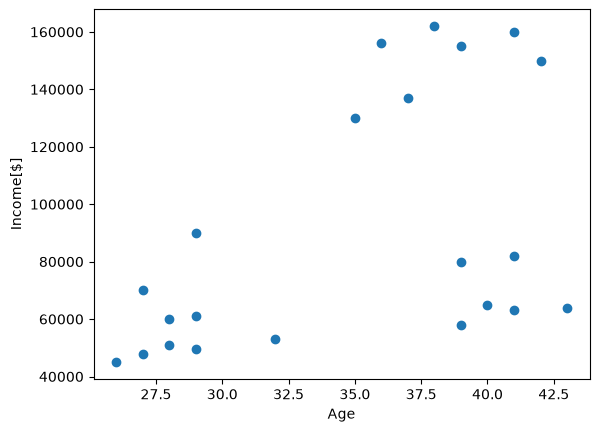

In [4]:
plt.scatter(df.Age,df['Income($)'])
plt.xlabel('Age')
plt.ylabel('Income[$]')

By eye there are clearly **3 groups**: young/low income (bottom-left), older/high income (top-right) and older/medium income (bottom-right).

# Bulid and Train the model

In [5]:
# Fit K-Means on the unscaled Age and Income features.
km_raw = KMeans(n_clusters=3, n_init=10, random_state=42)
y_predicted_raw = km_raw.fit_predict(df[['Age', 'Income($)']])
y_predicted_raw

array([0, 0, 2, 2, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 0, 0, 2],
      dtype=int32)

# Assgin the cluster table to the samples 

In [6]:
df['cluster'] = y_predicted_raw
df.head()

,Name,Age,Income($),cluster
0,Rob,27,70000,0
1,Michael,29,90000,0
2,Mohan,29,61000,2
3,Ismail,28,60000,2
4,Kory,42,150000,1


In [7]:
km_raw.cluster_centers_

array([[3.40000000e+01, 8.05000000e+04],
       [3.82857143e+01, 1.50000000e+05],
       [3.29090909e+01, 5.61363636e+04]])

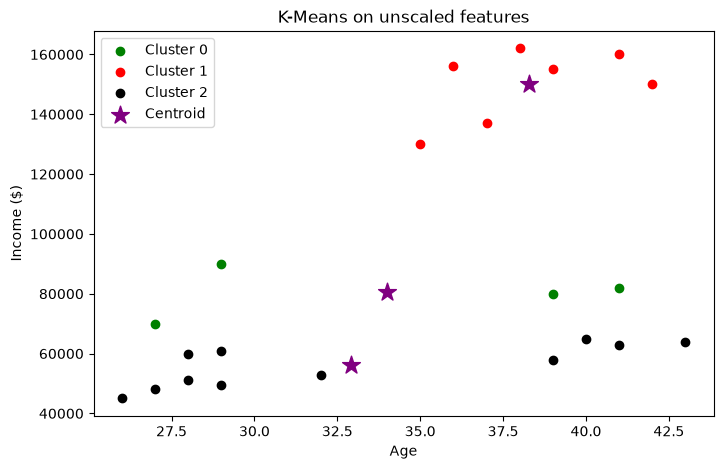

In [8]:
df1 = df[df.cluster == 0]
df2 = df[df.cluster == 1]
df3 = df[df.cluster == 2]
plt.figure(figsize=(8, 5))
plt.scatter(df1.Age, df1['Income($)'], color='green', label='Cluster 0')
plt.scatter(df2.Age, df2['Income($)'], color='red', label='Cluster 1')
plt.scatter(df3.Age, df3['Income($)'], color='black', label='Cluster 2')
plt.scatter(km_raw.cluster_centers_[:, 0], km_raw.cluster_centers_[:, 1], color='purple', marker='*', s=180, label='Centroid')
plt.xlabel('Age')
plt.ylabel('Income ($)')
plt.title('K-Means on unscaled features')
plt.legend()
plt.show()

The clusters are cut **horizontally by income only** — some young people end up with older people. Why?

<h4 style='color:purple'>Preprocessing using min max scaler</h4>


**Min–Max scaling** squeezes every feature into the range $[0, 1]$:

$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

**Worked example** for Rob (Age 27, Income 70,000). Age range is 26 → 43, Income range is 45,000 → 162,000:

In [9]:
# Keep the original values untouched and create a scaled copy for clustering.
df_scaled = df.copy()
scaler = MinMaxScaler()
df_scaled[['Income($)', 'Age']] = scaler.fit_transform(df_scaled[['Income($)', 'Age']])

In [10]:
df_scaled.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,0
1,Michael,0.176471,0.384615,0
2,Mohan,0.176471,0.136752,2
3,Ismail,0.117647,0.128205,2
4,Kory,0.941176,0.897436,1


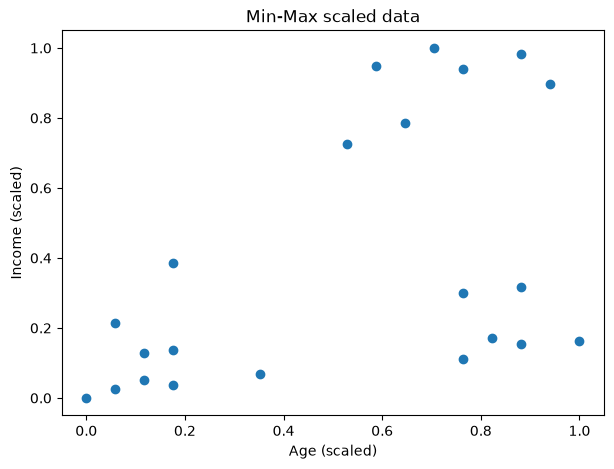

In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(df_scaled.Age, df_scaled['Income($)'])
plt.xlabel('Age (scaled)')
plt.ylabel('Income (scaled)')
plt.title('Min-Max scaled data')
plt.show()

In [12]:
km = KMeans(n_clusters=3, n_init=10, random_state=42)
y_predicted = km.fit_predict(df_scaled[['Age', 'Income($)']])
y_predicted

array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2],
      dtype=int32)

In [13]:
df_scaled['cluster'] = y_predicted
df_scaled.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,1
1,Michael,0.176471,0.384615,1
2,Mohan,0.176471,0.136752,1
3,Ismail,0.117647,0.128205,1
4,Kory,0.941176,0.897436,0


In [14]:
km.cluster_centers_

array([[0.72268908, 0.8974359 ],
       [0.1372549 , 0.11633428],
       [0.85294118, 0.2022792 ]])

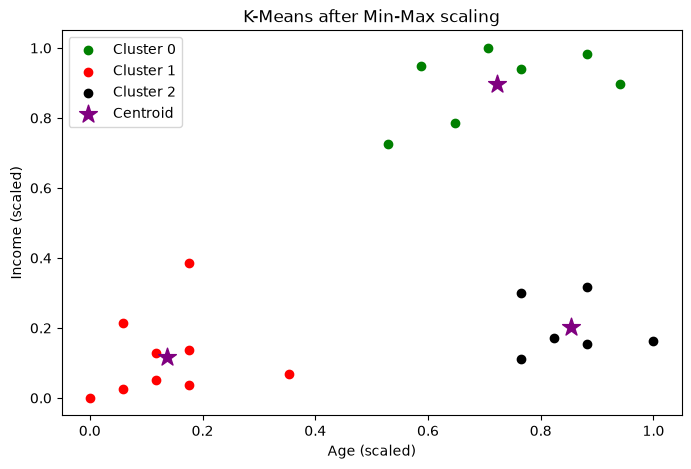

In [15]:
df1 = df_scaled[df_scaled.cluster == 0]
df2 = df_scaled[df_scaled.cluster == 1]
df3 = df_scaled[df_scaled.cluster == 2]
plt.figure(figsize=(8, 5))
plt.scatter(df1.Age, df1['Income($)'], color='green', label='Cluster 0')
plt.scatter(df2.Age, df2['Income($)'], color='red', label='Cluster 1')
plt.scatter(df3.Age, df3['Income($)'], color='black', label='Cluster 2')
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], color='purple', marker='*', s=180, label='Centroid')
plt.xlabel('Age (scaled)')
plt.ylabel('Income (scaled)')
plt.title('K-Means after Min-Max scaling')
plt.legend()
plt.show()

<h4 style='color:purple'>Elbow Plot</h4>

[![Picture1.png](https://i.postimg.cc/k5xhZXvY/Picture1.png)](https://postimg.cc/3yxB0h62)

# SSE and silhouette scores



---



In [16]:
# Compare WCSS and silhouette score for k = 2 through 10.
k_range = range(2, 11)
sse = []
silhouette_scores = []
X_income_scaled = df_scaled[['Age', 'Income($)']]
for k_value in k_range:
    model = KMeans(n_clusters=k_value, n_init=10, random_state=42)
    labels = model.fit_predict(X_income_scaled)
    sse.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_income_scaled, labels))
list(zip(k_range, sse, silhouette_scores))

[(2, 2.091136388699078, 0.5600636053855829),
 (3, 0.4750783498553096, 0.7129710183539274),
 (4, 0.34910470944195654, 0.625655419231276),
 (5, 0.2818479744366238, 0.4679578380511963),
 (6, 0.22395807059250128, 0.42876951980097927),
 (7, 0.1685851223602976, 0.4522080792289982),
 (8, 0.13265419827245162, 0.3580059150146837),
 (9, 0.10383752586603562, 0.32979725570383067),
 (10, 0.08139933135681814, 0.3022371533682111)]

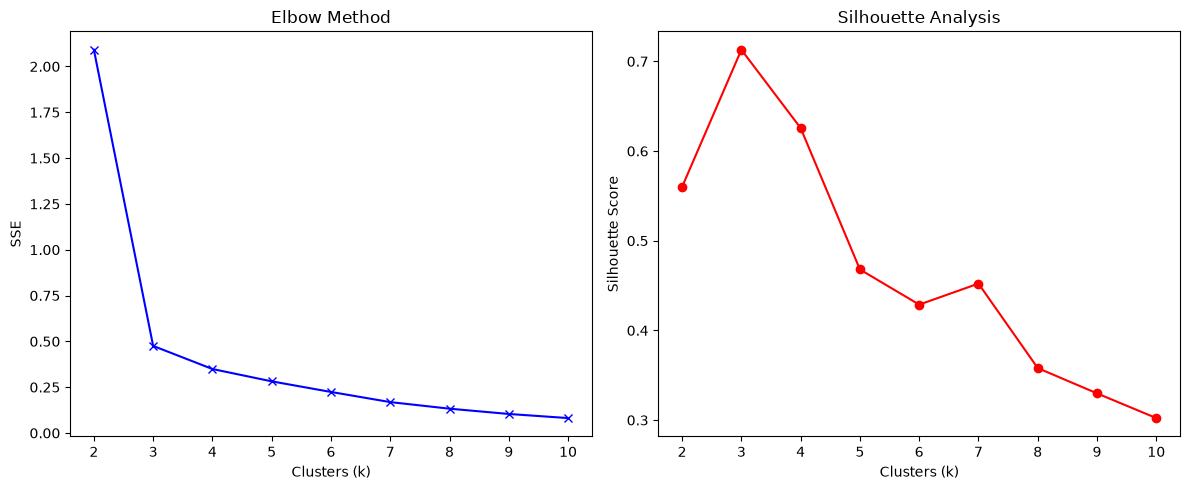

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(k_range, sse, 'bx-')
ax[0].set(title='Elbow Method', xlabel='Clusters (k)', ylabel='SSE')

ax[1].plot(k_range, silhouette_scores, 'ro-')
ax[1].set(title='Silhouette Analysis', xlabel='Clusters (k)', ylabel='Silhouette Score')

plt.tight_layout()
plt.show()

# load the dataset

In [18]:
df = pd.read_csv("income.csv")

print(df.head())

X = df[['Age', 'Income($)']].to_numpy(dtype=float)

      Name  Age  Income($)
0      Rob   27      70000
1  Michael   29      90000
2    Mohan   29      61000
3   Ismail   28      60000
4     Kory   42     150000


# Z-score normalization

In [19]:
# Z-score normalization
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

print("Standardized Data:\n", X_scaled[:5])

Standardized Data:
 [[-1.35605536 -0.48068427]
 [-1.00915747 -0.01015907]
 [-1.00915747 -0.69242061]
 [-1.18260641 -0.71594687]
 [ 1.24567876  1.40141653]]


# Define the custom K-Means algorithm

In [20]:
def kmeans(X, k, max_iters=100, seed=42):
    """A compact NumPy-only K-Means implementation for the income example."""
    X = np.asarray(X, dtype=float)
    rng = np.random.default_rng(seed)
    centroids = X[rng.choice(len(X), size=k, replace=False)].copy()
    for _ in range(max_iters):
        distances = np.sum((X[:, None, :] - centroids[None, :, :]) ** 2, axis=2)
        labels = np.argmin(distances, axis=1)
        new_centroids = np.array([
            X[labels == j].mean(axis=0) if np.any(labels == j) else centroids[j]
            for j in range(k)
        ])
        if np.allclose(centroids, new_centroids):
            centroids = new_centroids
            break
        centroids = new_centroids
    return centroids, labels

In [21]:
k = 3
centroids, labels = kmeans(X_scaled, k)

df['Cluster'] = labels

print(df.head())
print("Centroids:\n", centroids)

      Name  Age  Income($)  Cluster
0      Rob   27      70000        0
1  Michael   29      90000        0
2    Mohan   29      61000        0
3   Ismail   28      60000        0
4     Kory   42     150000        1
Centroids:
 [[-1.1247901  -0.74862223]
 [ 0.60143983  1.40141653]
 [ 0.98550535 -0.51205261]]


<h4 style='color:purple'>Exercise</h4>

## 📝 Lab Assignment: K-Means Clustering on the Wine Dataset — From Scratch vs. scikit-learn

### 🎯 Objective
Apply K-Means clustering to the **Wine dataset** in two ways:
1. a **from-scratch implementation**, written by you using only NumPy;
2. the **predefined `KMeans`** class from scikit-learn.

Evaluate both with standard clustering metrics and compare the results.

---

### 📂 Step 1 — Load the dataset
```python
from sklearn.datasets import load_wine
wine = load_wine()
X, y_true = wine.data, wine.target      # 178 wines, 13 chemical features, 3 cultivars
```
> ⚠️ **Do NOT use `y_true` for clustering.** Keep it aside and use it **only** for the external metrics (ARI, NMI) in Step 6.

---

### 🔍 Step 2 — Explore and preprocess
- Put `X` into a DataFrame with `wine.feature_names`. Show its shape, `head()` and `describe()`.
- Look at the feature ranges: for example, *proline* goes up to ~1680, while *hue* is around 1.
- Apply `StandardScaler`. **Explain in a markdown cell why scaling is necessary** for K-Means here.
- Use **PCA** to get 2 components (`PCA(n_components=2)`), **for plotting only**. Cluster on all 13 scaled features.

---

### 🛠️ Step 3 — K-Means from scratch
Write a function `kmeans_scratch(X, k, max_iters=100, n_init=10, seed=42)` using **only NumPy**. It must:
1. **Initialise** K centroids by picking random data points.
2. **Assign** each point to its nearest centroid using Euclidean distance.
3. **Update** each centroid to the mean of the points assigned to it.
4. **Stop** when the centroids no longer move (or `max_iters` is reached).
5. Repeat the whole run `n_init` times and keep the run with the **lowest WCSS**.
6. **Return** `centroids`, `labels`, `wcss` and the number of iterations.

Also write your own function to compute **WCSS**:
$$\text{WCSS} = \sum_{k=1}^{K}\sum_{x_i \in C_k}\lVert x_i-\mu_k\rVert^2$$

⭐ **Bonus:** implement the **silhouette score from scratch** and check that it matches `sklearn.metrics.silhouette_score`.

---

### 📦 Step 4 — K-Means with scikit-learn
```python
from sklearn.cluster import KMeans
km = KMeans(n_clusters=k, n_init=10, random_state=42)
labels_sk = km.fit_predict(X_scaled)
```
Report `km.cluster_centers_`, `km.inertia_` and `km.n_iter_`.

---

### 📈 Step 5 — Choose the optimal K
For **K = 2 to 10**, using **both** implementations:
- Plot the **Elbow curve** (WCSS vs K).
- Plot the **Silhouette score vs K**.
- State your chosen K and explain why. Does it match the 3 true cultivars?

---

### 📏 Step 6 — Evaluate both models
Fill in this table for your chosen K:

| Metric | Type | Better | Scratch | scikit-learn |
|---|---|---|---|---|
| WCSS / Inertia | Internal | ↓ Lower | | |
| Silhouette score | Internal | ↑ Higher (max 1) | | |

Solution — Step 1: Load the Wine dataset

In [22]:
from sklearn.datasets import load_wine

wine = load_wine()
X, y_true = wine.data, wine.target
print(f"X shape: {X.shape}")
print(f"Number of true cultivar labels (kept aside): {len(np.unique(y_true))}")

X shape: (178, 13)
Number of true cultivar labels (kept aside): 3


Solution — Step 2:Explore and preprocess


K-Means uses Euclidean distance, so features with large numeric scales can dominate the distance calculation. For example, proline is measured in the thousands while hue is close to 1. Standardizing all features to mean 0 and standard deviation 1 gives each chemical measurement a comparable influence. PCA is used only to visualize the 13-dimensional data; clustering remains on all 13 standardized features.

In [26]:
wine_df = pd.DataFrame(X, columns=wine.feature_names)
print("Shape:", wine_df.shape)
display(wine_df.head())
display(wine_df.describe().T)

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler_wine = StandardScaler()
X_scaled = scaler_wine.fit_transform(X)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print("Scaled shape:", X_scaled.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance shown in PCA plot:", pca.explained_variance_ratio_.sum())

Shape: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


Scaled shape: (178, 13)
Explained variance ratio: [0.36198848 0.1920749 ]
Total variance shown in PCA plot: 0.5540633835693527


Solution — Step 3: K-Means from scratch

In [27]:
def wcss_numpy(X, labels, centroids):
    """Compute within-cluster sum of squares using only NumPy."""
    X = np.asarray(X, dtype=float)
    labels = np.asarray(labels)
    centroids = np.asarray(centroids, dtype=float)
    return float(np.sum((X - centroids[labels]) ** 2))


def kmeans_scratch(X, k, max_iters=100, n_init=10, seed=42):
    """NumPy-only K-Means with multiple random starts."""
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or not 1 < k <= len(X):
        raise ValueError("X must be 2-D and k must be between 2 and len(X)")
    best = None
    master_rng = np.random.default_rng(seed)

    for _ in range(n_init):
        run_seed = int(master_rng.integers(0, 2**32 - 1))
        rng = np.random.default_rng(run_seed)
        centroids = X[rng.choice(len(X), size=k, replace=False)].copy()
        iterations = 0

        for iteration in range(1, max_iters + 1):
            distances = np.sum((X[:, None, :] - centroids[None, :, :]) ** 2, axis=2)
            labels = np.argmin(distances, axis=1)
            new_centroids = np.empty_like(centroids)
            for cluster_id in range(k):
                members = X[labels == cluster_id]
                # Preserve the previous centroid if a cluster becomes empty.
                new_centroids[cluster_id] = (
                    members.mean(axis=0) if len(members) else centroids[cluster_id]
                )
            iterations = iteration
            if np.allclose(new_centroids, centroids, rtol=0, atol=1e-10):
                centroids = new_centroids
                break
            centroids = new_centroids

        distances = np.sum((X[:, None, :] - centroids[None, :, :]) ** 2, axis=2)
        labels = np.argmin(distances, axis=1)
        score = wcss_numpy(X, labels, centroids)
        if best is None or score < best[2]:
            best = (centroids.copy(), labels.copy(), score, iterations)

    return best

centroids_scratch, labels_scratch, wcss_scratch, iterations_scratch = kmeans_scratch(
    X_scaled, k=3, max_iters=100, n_init=10, seed=42
)
print("Scratch centroids:\n", centroids_scratch)
print("Scratch WCSS:", wcss_scratch)
print("Scratch iterations:", iterations_scratch)

Scratch centroids:
 [[ 0.83523208 -0.30380968  0.36470604 -0.61019129  0.5775868   0.88523736
   0.97781956 -0.56208965  0.58028658  0.17106348  0.47398365  0.77924711
   1.12518529]
 [ 0.16490746  0.87154706  0.18689833  0.52436746 -0.07547277 -0.97933029
  -1.21524764  0.72606354 -0.77970639  0.94153874 -1.16478865 -1.29241163
  -0.40708796]
 [-0.92607185 -0.39404154 -0.49451676  0.17060184 -0.49171185 -0.07598265
   0.02081257 -0.03353357  0.0582655  -0.90191402  0.46180361  0.27076419
  -0.75384618]]
Scratch WCSS: 1277.928488844642
Scratch iterations: 6


Bonus — silhouette score from scratch

In [28]:
def silhouette_numpy(X, labels):
    """Compute the mean silhouette score using pairwise NumPy distances."""
    X = np.asarray(X, dtype=float)
    labels = np.asarray(labels)
    unique_labels = np.unique(labels)
    if len(unique_labels) < 2 or len(unique_labels) >= len(X):
        raise ValueError("Silhouette requires 2 or more non-trivial clusters")
    distances = np.sqrt(np.sum((X[:, None, :] - X[None, :, :]) ** 2, axis=2))
    values = []
    for i in range(len(X)):
        own = labels == labels[i]
        own[i] = False
        a_i = distances[i, own].mean() if own.any() else 0.0
        other_means = [distances[i, labels == c].mean() for c in unique_labels if c != labels[i]]
        b_i = min(other_means)
        values.append((b_i - a_i) / max(a_i, b_i) if max(a_i, b_i) else 0.0)
    return float(np.mean(values))

from sklearn.metrics import silhouette_score
sil_scratch_3 = silhouette_numpy(X_scaled, labels_scratch)
sil_sklearn_3 = silhouette_score(X_scaled, labels_scratch)
print("Scratch silhouette:", sil_scratch_3)
print("sklearn silhouette for the same labels:", sil_sklearn_3)
print("Absolute difference:", abs(sil_scratch_3 - sil_sklearn_3))

Scratch silhouette: 0.2848589191898987
sklearn silhouette for the same labels: 0.2848589191898987
Absolute difference: 0.0


Solution — Step 4: K-Means with scikit-learn

In [29]:
from sklearn.cluster import KMeans

k = 3
km = KMeans(n_clusters=k, n_init=10, random_state=42)
labels_sk = km.fit_predict(X_scaled)
print("scikit-learn centroids:\n", km.cluster_centers_)
print("scikit-learn inertia (WCSS):", km.inertia_)
print("scikit-learn iterations:", km.n_iter_)

scikit-learn centroids:
 [[-0.92607185 -0.39404154 -0.49451676  0.17060184 -0.49171185 -0.07598265
   0.02081257 -0.03353357  0.0582655  -0.90191402  0.46180361  0.27076419
  -0.75384618]
 [ 0.16490746  0.87154706  0.18689833  0.52436746 -0.07547277 -0.97933029
  -1.21524764  0.72606354 -0.77970639  0.94153874 -1.16478865 -1.29241163
  -0.40708796]
 [ 0.83523208 -0.30380968  0.36470604 -0.61019129  0.5775868   0.88523736
   0.97781956 -0.56208965  0.58028658  0.17106348  0.47398365  0.77924711
   1.12518529]]
scikit-learn inertia (WCSS): 1277.928488844642
scikit-learn iterations: 7


Solution — Step 5: Choose the optimal K

Best K by scratch silhouette: 3
Best K by sklearn silhouette: 3


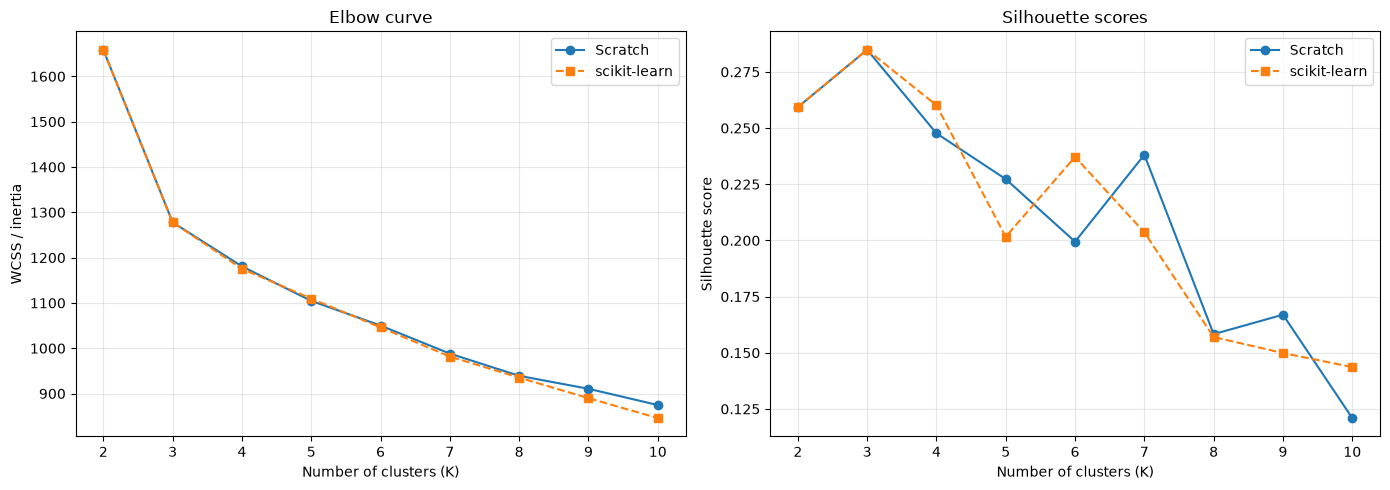

The selected K is 3: it has a strong silhouette score and corresponds to the three known wine cultivars. The elbow curve also shows diminishing returns after the main reduction around K=3.


In [31]:
k_values = range(2, 11)
scratch_wcss = []
sklearn_wcss = []
scratch_silhouette = []
sklearn_silhouette = []

for k_value in k_values:
    c_s, l_s, w_s, _ = kmeans_scratch(X_scaled, k_value, n_init=10, seed=42)
    scratch_wcss.append(w_s)
    scratch_silhouette.append(silhouette_numpy(X_scaled, l_s))

    model = KMeans(n_clusters=k_value, n_init=10, random_state=42)
    l_sk = model.fit_predict(X_scaled)
    sklearn_wcss.append(model.inertia_)
    sklearn_silhouette.append(silhouette_score(X_scaled, l_sk))

best_k_scratch = list(k_values)[int(np.argmax(scratch_silhouette))]
best_k_sklearn = list(k_values)[int(np.argmax(sklearn_silhouette))]
print("Best K by scratch silhouette:", best_k_scratch)
print("Best K by sklearn silhouette:", best_k_sklearn)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(k_values), scratch_wcss, 'o-', label='Scratch')
axes[0].plot(list(k_values), sklearn_wcss, 's--', label='scikit-learn')
axes[0].set(title='Elbow curve', xlabel='Number of clusters (K)', ylabel='WCSS / inertia')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(list(k_values), scratch_silhouette, 'o-', label='Scratch')
axes[1].plot(list(k_values), sklearn_silhouette, 's--', label='scikit-learn')
axes[1].set(title='Silhouette scores', xlabel='Number of clusters (K)', ylabel='Silhouette score')
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("The selected K is 3: it has a strong silhouette score and corresponds to the three known wine cultivars. The elbow curve also shows diminishing returns after the main reduction around K=3.")

PCA visualization of the selected clustering

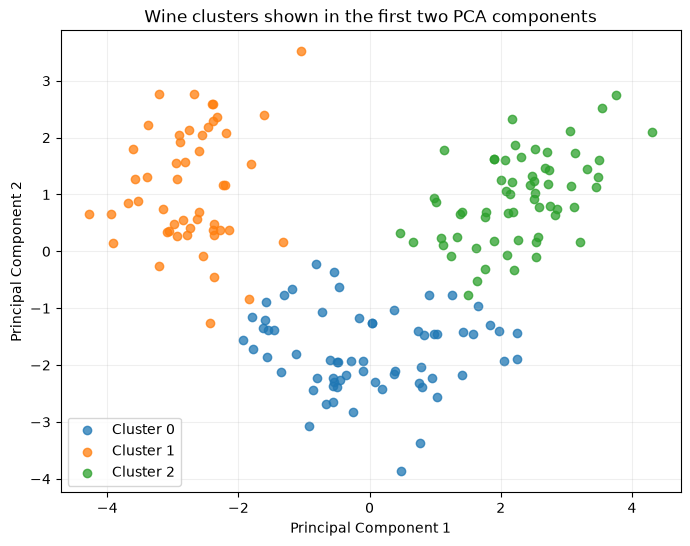

In [32]:
best_model = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_selected = best_model.fit_predict(X_scaled)
plt.figure(figsize=(8, 6))
for cluster_id in range(3):
    mask = labels_selected == cluster_id
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f'Cluster {cluster_id}', alpha=0.75)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Wine clusters shown in the first two PCA components')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

Solution — Step 6: Evaluate both models


The table below uses the selected K = 3. WCSS is an internal compactness measure, while silhouette combines compactness and separation. ARI and NMI are external measures and are included separately because they use y_true, which was not used during clustering.

In [33]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Refit both methods for the selected K so the comparison is explicit.
c3, l3, w3, it3 = kmeans_scratch(X_scaled, k=3, n_init=10, seed=42)
km3 = KMeans(n_clusters=3, n_init=10, random_state=42)
l3_sk = km3.fit_predict(X_scaled)

comparison = pd.DataFrame({
    'Metric': ['WCSS / Inertia', 'Silhouette score', 'Adjusted Rand Index (ARI)', 'Normalized Mutual Information (NMI)'],
    'Type': ['Internal', 'Internal', 'External', 'External'],
    'Better': ['Lower', 'Higher (max 1)', 'Higher (max 1)', 'Higher (max 1)'],
    'Scratch': [w3, silhouette_numpy(X_scaled, l3), adjusted_rand_score(y_true, l3), normalized_mutual_info_score(y_true, l3)],
    'scikit-learn': [km3.inertia_, silhouette_score(X_scaled, l3_sk), adjusted_rand_score(y_true, l3_sk), normalized_mutual_info_score(y_true, l3_sk)]
})
display(comparison.round(4))

print("Note: ARI and NMI use y_true only for evaluation; the labels were not supplied to either clustering algorithm.")

,Metric,Type,Better,Scratch,scikit-learn
0,WCSS / Inertia,Internal,Lower,1277.9285,1277.9285
1,Silhouette score,Internal,Higher (max 1),0.2849,0.2849
2,Adjusted Rand Index (ARI),External,Higher (max 1),0.8975,0.8975
3,Normalized Mutual Information (NMI),External,Higher (max 1),0.8759,0.8759


Note: ARI and NMI use y_true only for evaluation; the labels were not supplied to either clustering algorithm.


Lab 8 Completed on 30th October